# WASP-21 b: periodo, masa y semi-amplitud a partir de velocidad radial

**Objetivo.** Estimar el periodo orbital y la masa mínima del exoplaneta WASP-21 b usando mediciones de velocidad radial (RV) de su estrella anfitriona.

**Datos.** Curva de velocidad radial pública del [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/) (15 mediciones con incertidumbre).

**Métodos.**
1. Periodograma de Lomb-Scargle para encontrar el periodo.
2. Curva de fase y ajuste sinusoidal (órbita circular).
3. Masa del planeta a partir de la semi-amplitud *K*.
4. Ajuste por mínimos cuadrados ponderados (`scipy.optimize.curve_fit`) con incertidumbres en los parámetros.

**Dependencias:** ver `requirements.txt`.

In [3]:
import sys
if "google.colab" in sys.modules:
    %pip install -q gatspy

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from gatspy import periodic

## 1. Carga y limpieza de datos

In [5]:
exo = pd.read_table('https://exoplanetarchive.ipac.caltech.edu/data/ExoData/0300/0300107/data/UID_0300107_RVC_003.tbl', comment='\\', sep=r'\s+')

In [6]:
exo=exo[exo.columns[:3]][2:]
exo.columns=('Dia Juliano','Velocidad Radial','Incertidumbre')

In [7]:
#exo=exo.dropna()
exo=exo.reset_index(drop=True)

In [8]:
exo['Velocidad Radial']=exo['Velocidad Radial'].astype('float')
exo['Dia Juliano']=exo['Dia Juliano'].astype('float')
exo['Incertidumbre']=exo['Incertidumbre'].astype('float')
exo

,Dia Juliano,Velocidad Radial,Incertidumbre
0,2.454707e+06,-89400.1,10.0
1,2.454710e+06,-89479.2,3.3
2,2.454711e+06,-89428.7,3.8
3,2.454750e+06,-89430.9,3.6
4,2.454755e+06,-89415.4,3.1
5,2.454756e+06,-89431.7,2.5
6,2.454761e+06,-89463.9,2.2
7,2.454762e+06,-89478.2,2.7
8,2.454764e+06,-89404.0,3.1
9,2.455112e+06,-89479.7,2.9


## 2. Velocidad radial vs. tiempo

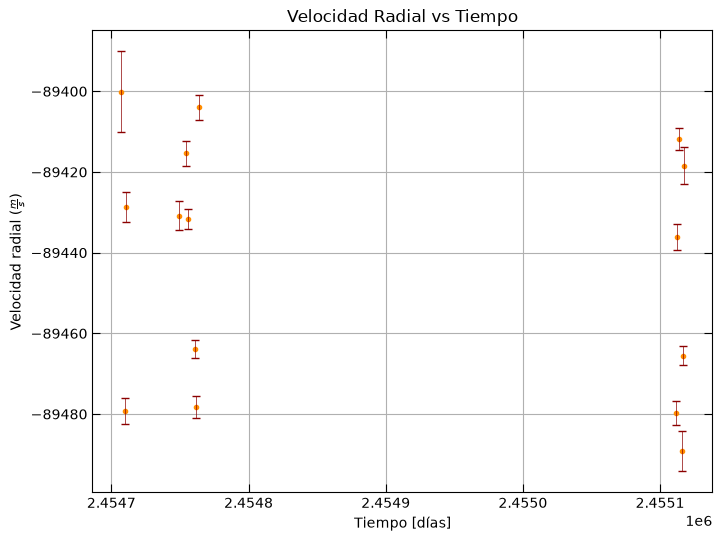

In [9]:
# Grafíca
fig = plt.figure(figsize=(8, 6))

plt.plot(exo['Dia Juliano'],exo['Velocidad Radial'],".",color="darkorange")
plt.title('Velocidad Radial vs Tiempo',size=12)
plt.errorbar(exo['Dia Juliano'],exo['Velocidad Radial'],exo['Incertidumbre'],color="darkred", fmt='none',capsize=3, elinewidth=0.5)
plt.xlabel(r"Tiempo [días]",fontsize=10)
plt.ylabel(r"Velocidad radial ($\frac{m}{s}$)",fontsize=10)
plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6)
plt.grid()
plt.show()

## 3. Periodograma de Lomb-Scargle

El periodograma (que admite muestreo irregular y pesa por incertidumbre) muestra un pico claro alrededor de 4.3 días. Se refina el periodo restringiendo la búsqueda a un rango estrecho alrededor de ese pico.

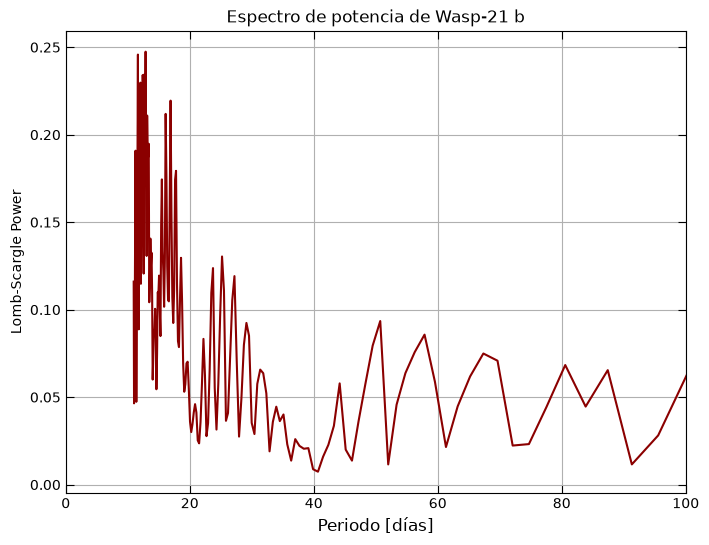

Finding optimal frequency:
 - Estimated peak width = 0.0153
 - Using 5 steps per peak; omega_step = 0.00306
 - User-specified period range:  4 to 4.4
 - Computing periods at 48 steps
Zooming-in on 5 candidate peaks:
 - Computing periods at 1000 steps
El periodo orbital para el planeta es 4.3241 dias


In [10]:
#Aplicamos el Periodograma LombScargle a nuestros datos, para obtener el periodo:
freq, radV = LombScargle(exo['Dia Juliano'],exo['Velocidad Radial'],exo['Incertidumbre']).autopower()

#Graficamos
fig = plt.figure(figsize=(8, 6))
plt.plot(1/freq, radV,'darkred')
plt.xlabel(r"Periodo [días]",fontsize=12)
plt.xlim(0,100)
plt.ylabel("Lomb-Scargle Power")
plt.title("Espectro de potencia de Wasp-21 b",fontsize=12)
plt.grid()
plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6)
plt.show()


# A partir de la serie de tiempo, damos un rango estimado donde podría estar el periodo:
model = periodic.LombScargle(fit_period=True)
model.optimizer.period_range = (4,4.4)
model.fit(exo['Dia Juliano'], exo['Velocidad Radial'],)

# A partir de la serie de tiempo, damos un rango estimado donde podría estar el periodo:
P=model.best_period
print("El periodo orbital para el planeta es %.4f"% P, "dias")

## 4. Curva de fase

Se resta la velocidad media (velocidad sistémica) y se pliegan los datos con el periodo encontrado. Las incertidumbres se conservan tal como las reporta la fuente.

In [11]:
# Se centra la velocidad radial en su media (velocidad sistémica).
# Las incertidumbres NO se transforman: se usan tal como vienen de la fuente.
exo['Velocidad Radial'] = exo['Velocidad Radial'] - exo['Velocidad Radial'].mean()

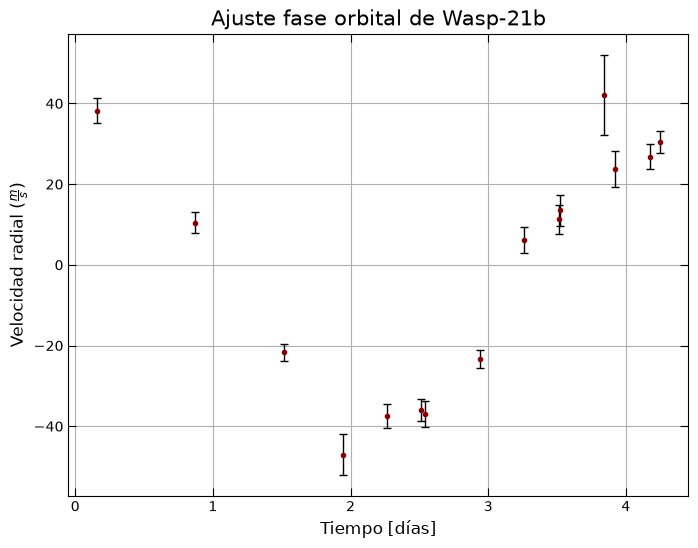

In [12]:
# Datos
jd = np.array(exo['Dia Juliano']%P)
rv = np.array(exo['Velocidad Radial'])

# Error
rverr = np.array(exo['Incertidumbre'])

#Gráfica
fig = plt.figure(figsize=(8, 6))
plt.errorbar(jd, rv, yerr=rverr,color="black" ,fmt='none',capsize=3, elinewidth=1)
plt.plot(jd,rv,'.',color="darkred")
plt.title("Ajuste fase orbital de Wasp-21b",size=15)
plt.xlabel(r"Tiempo [días]",fontsize=12)
plt.ylabel(r"Velocidad radial ($\frac{m}{s}$)",fontsize=12)
plt.grid()
plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6)

plt.show()

## 5. Semi-amplitud y masa del planeta (estimación simple)

Primera aproximación: *K* = (máx − mín)/2 de la curva de velocidad. La masa mínima se obtiene con

$$ M_p \sin i = K \, \frac{M_J}{28.4\ \mathrm{m/s}} \left(\frac{P}{1\ \mathrm{yr}}\right)^{1/3} \left(\frac{M_\star}{M_\odot}\right)^{2/3} \sqrt{1-e^2} $$

con parámetros estelares y orbitales de la literatura (Chen; Bouchy et al. 2010; Alderson et al. 2020).

La semi-amplitud es de: 44.549999999995634 m/s
44.549889857191744


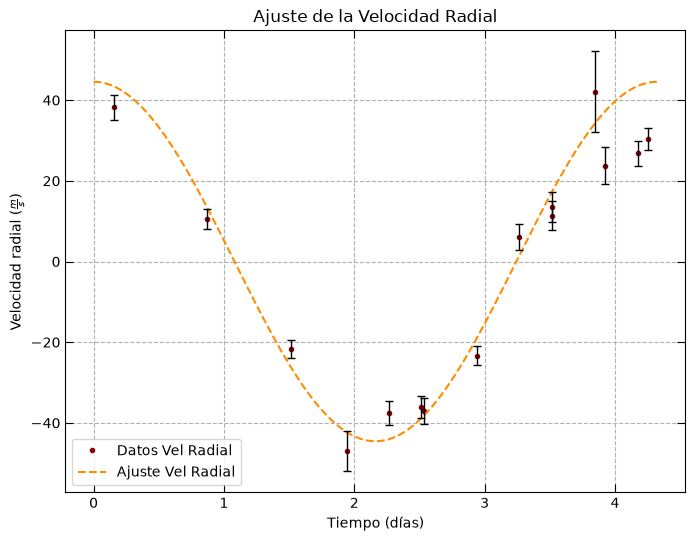

In [13]:
# Ajuste de los datos
w=2*np.pi/P
x=np.linspace(0,P,1000)
K = float((max(exo['Velocidad Radial'])-min(exo['Velocidad Radial']))/2)

def fit(x):
  return K*np.cos((w*x))

print (f"La semi-amplitud es de: {K} m/s")

y= fit(x)
err=exo['Velocidad Radial']-fit(exo['Dia Juliano'])
K=(y.max()-y.min())/2
print((y.max()-y.min())/2)
#Gráfica
fig = plt.figure(figsize=(8, 6))
plt.plot(exo['Dia Juliano'] %P, exo['Velocidad Radial'], '.',color='darkred',label="Datos Vel Radial")

plt.plot(x,y,'--',color="darkorange", label="Ajuste Vel Radial")
plt.title("Ajuste de la Velocidad Radial",fontsize=12)
plt.xlabel(r"Tiempo (días)",fontsize=10)
plt.ylabel(r"Velocidad radial ($\frac{m}{s}$)",fontsize=10)
plt.errorbar(jd, rv, yerr=rverr,color="black" ,fmt='none',capsize=3, elinewidth=1)
plt.legend()
plt.grid()
plt.tick_params(axis='both', which='both', bottom=True, top=True, left=True, right=True, direction='in', length=6,grid_linestyle='--')
plt.show()

In [14]:
#---------------------------Calculo de la Masa---------------------------------
#------Datos
Mj = 1.898e27         #kg
M_sun = 1.989e30      #kg
M_s = 0.890*M_sun #kg Masa de estrella \\Chen
#M_s = 1.080000*M_sun #kg Masa de estrella \\TicV8 Alderson

ex=0

i = 88.75*np.pi/180 #\Bouchy
#i = 86.82*np.pi/180 #\Alderson
#i = 88.28*np.pi/180 #\Chen
mpt = 0.300*Mj #kg \\Bouchy
#mpt = 0.29*Mj #kg \\Alderson

mp=(K*Mj*(1/28.4)*((P/365.24)**(1/3))*((M_s/M_sun)**(2/3))*(1-ex**2)**(1/2))/np.sin(i)

print("La masa hallada es de:",mp/Mj,"La m teorica es: ",mpt/Mj)

print("El error relativo es: ", np.abs((mpt/Mj-mp/Mj)/(mpt/Mj))*100)

La masa hallada es de: 0.33087639309960093 La m teorica es:  0.3
El error relativo es:  10.292131033200313


El error relativo (~10 %) frente al valor publicado se debe, en buena parte, a que esta *K* es una estimación gruesa (máx−mín sobre solo 15 puntos con ruido), sin pesar por incertidumbre. La siguiente sección lo mejora.

## 6. Ajuste por mínimos cuadrados ponderados

Se ajusta un modelo de órbita circular

$$ v(t) = K \sin\!\left(\frac{2\pi (t - t_0)}{P} + \varphi\right) + \gamma $$

con $K$, $P$, $\varphi$ y $\gamma$ libres, ponderando por $1/\sigma^2$. Se prueban varias fases iniciales para evitar mínimos locales y se reportan las incertidumbres de los parámetros (`absolute_sigma=True`).

> Ejecuta esta sección y guarda el notebook con las salidas para que se vean en GitHub.

In [15]:
from scipy.optimize import curve_fit

t = exo['Dia Juliano'].to_numpy()
y = exo['Velocidad Radial'].to_numpy()      # m/s, centrada en su media
sigma = exo['Incertidumbre'].to_numpy()     # m/s
t0 = t.min()

def rv_circular(t, K, P, phi, gamma):
    return K * np.sin(2*np.pi*(t - t0)/P + phi) + gamma

best = None
for phi0 in np.linspace(0, 2*np.pi, 8, endpoint=False):
    try:
        popt, pcov = curve_fit(rv_circular, t, y, p0=[K, P, phi0, 0.0],
                               sigma=sigma, absolute_sigma=True, maxfev=20000)
    except RuntimeError:
        continue
    chi2 = np.sum(((y - rv_circular(t, *popt)) / sigma)**2)
    if best is None or chi2 < best[0]:
        best = (chi2, popt, pcov)

chi2, popt, pcov = best
if popt[0] < 0:                              # K > 0 por convención
    popt[0] = -popt[0]; popt[2] += np.pi
perr = np.sqrt(np.diag(pcov))
dof = len(t) - len(popt)

K_fit, P_fit = popt[0], popt[1]
print(f"K      = {K_fit:.2f} ± {perr[0]:.2f} m/s")
print(f"P      = {P_fit:.4f} ± {perr[1]:.4f} d")
print(f"chi2_r = {chi2/dof:.2f}  (dof = {dof})")

K      = 36.93 ± 1.09 m/s
P      = 4.3237 ± 0.0006 d
chi2_r = 2.53  (dof = 11)


In [16]:
# Masa con incertidumbre (Monte Carlo sobre K y P; no incluye errores de M_star ni de i)
def masa_Mj(K, P):
    mp = (K*Mj*(1/28.4)*((P/365.24)**(1/3))*((M_s/M_sun)**(2/3))*(1-ex**2)**0.5)/np.sin(i)
    return mp/Mj

rng = np.random.default_rng(42)
m_samples = masa_Mj(rng.normal(K_fit, perr[0], 20000), rng.normal(P_fit, perr[1], 20000))
m_med, m_lo, m_hi = np.percentile(m_samples, [50, 16, 84])
print(f"Masa = {m_med:.3f} (+{m_hi-m_med:.3f} / -{m_med-m_lo:.3f}) Mj   |   literatura (Bouchy): {mpt/Mj:.3f} Mj")

Masa = 0.274 (+0.008 / -0.008) Mj   |   literatura (Bouchy): 0.300 Mj


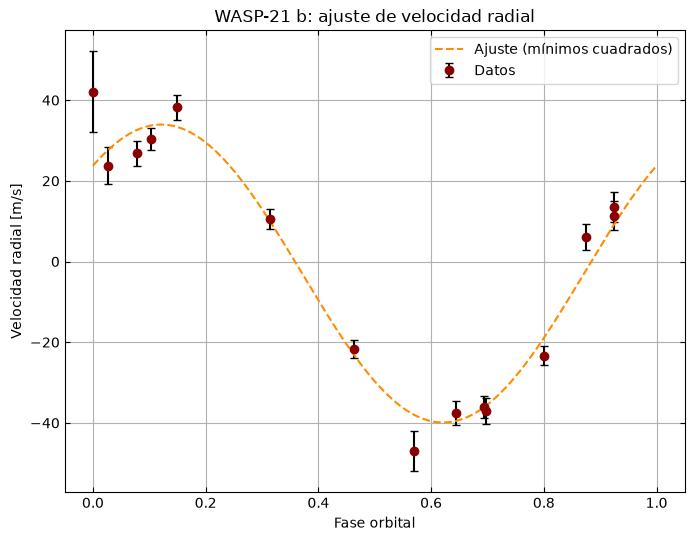

In [17]:
fase = ((t - t0) / P_fit) % 1
tt = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(fase, y, sigma, fmt='o', color='darkred', ecolor='black', capsize=3, label='Datos')
ax.plot(tt, rv_circular(t0 + tt*P_fit, *popt), '--', color='darkorange', label='Ajuste (mínimos cuadrados)')
ax.set(xlabel='Fase orbital', ylabel='Velocidad radial [m/s]', title='WASP-21 b: ajuste de velocidad radial')
ax.tick_params(direction='in', top=True, right=True); ax.grid(); ax.legend()
plt.show()

## Conclusiones

- El periodograma de Lomb-Scargle recupera un periodo orbital de **≈ 4.324 d**.
- La semi-amplitud simple da *K* ≈ 44.5 m/s y una masa de **≈ 0.33 M<sub>J</sub>**, ~10 % por encima de 0.30 M<sub>J</sub> (Bouchy et al.).
- El ajuste ponderado entrega *K* y *P* con incertidumbres propagadas a la masa.
- **Limitaciones:** solo 15 mediciones; órbita circular supuesta; la masa usa M<sub>★</sub> e inclinación *i* de la literatura sin propagar sus incertidumbres.